# Task 2 - Gestalt principles of grouping

Data: `stimuli_gestalt.csv` (284 rows, six panels) and `tips.csv`.
The data is almost the same in every panel, so any grouping you see comes from the **layout**, not the numbers.
Closure has 44 items on purpose (the gap is the stimulus) and similarity keeps its mixed-up positions, so nothing is "fixed".

In [2]:
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import clear_output

PANELS = ["proximity", "similarity", "enclosure", "continuity", "closure", "connection"]
MARKERS = {"circle": "o", "square": "s", "triangle": "^", "diamond": "D"}
SIZE_SCALE = 1  # if the dots look tiny or huge, change this (the size column is used as s)

g = pd.read_csv(r"C:\Users\Nas Graphy\Downloads\Data visdualtion\Week 2\stimuli_gestalt.csv")
print(g.shape)
g.groupby("panel").size()

(284, 8)


panel
closure       44
connection    48
continuity    48
enclosure     48
proximity     48
similarity    48
dtype: int64

## 1. Draw all six panels

In [2]:
def draw_panel(ax, name, lines=True, boxes=True, title=True):
    d = g[g["panel"] == name]

    for shape, part in d.groupby("shape"):
        if shape not in MARKERS:
            print("unknown shape:", shape, "- drawing a circle")
        ax.scatter(part["x"], part["y"], c=list(part["colour"]), marker=MARKERS.get(shape, "o"),
                   s=part["size"] * SIZE_SCALE, edgecolors="none", zorder=2)

    # enclosure: the boundaries are my job, one grey no-fill box round each group
    if name == "enclosure" and boxes:
        pad_x = 0.06 * (d["x"].max() - d["x"].min())
        pad_y = 0.06 * (d["y"].max() - d["y"].min())
        for _, grp in d.groupby("group"):
            x0, x1 = grp["x"].min() - pad_x, grp["x"].max() + pad_x
            y0, y1 = grp["y"].min() - pad_y, grp["y"].max() + pad_y
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False,
                                   edgecolor="grey", linewidth=1.6, zorder=1))

    # connection: one line per connector value (the two items that share it)
    if name == "connection" and lines:
        for _, pair in d.dropna(subset=["connector"]).groupby("connector"):
            if len(pair) == 2:
                ax.plot(pair["x"], pair["y"], color="0.45", linewidth=1.3, zorder=1)

    ax.set_aspect("equal")
    ax.margins(0.08)
    ax.axis("off")
    if title:
        ax.set_title(name, fontsize=13)

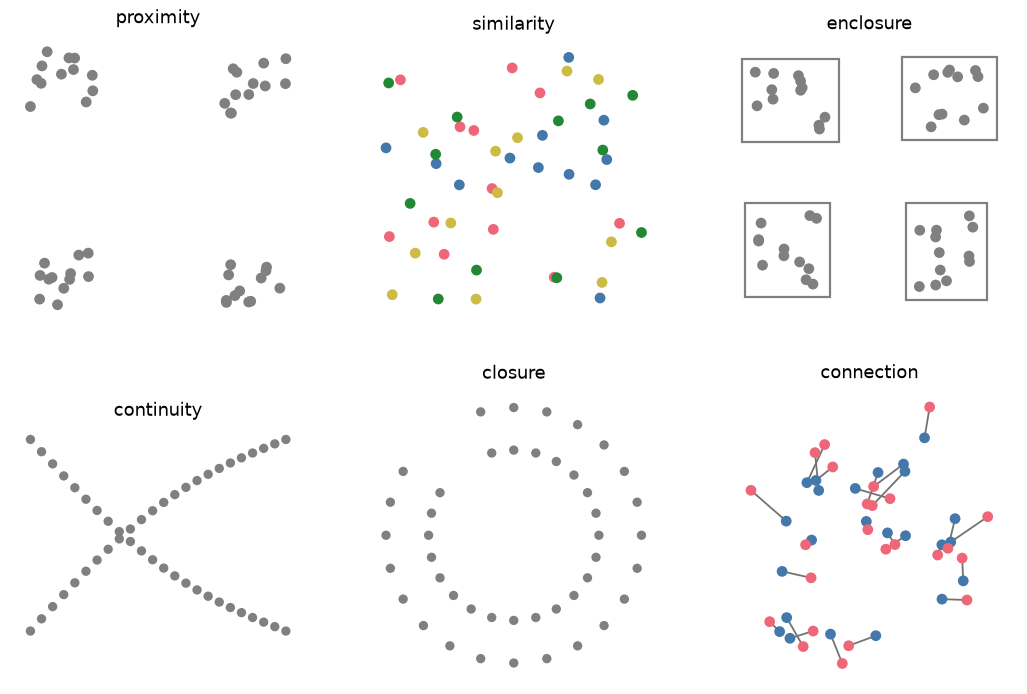

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, name in zip(axes.flat, PANELS):
    draw_panel(ax, name)
fig.savefig("task2_gestalt_panels.png", dpi=300, bbox_inches="tight")
plt.show()

Gestalt Principles of Perceptual Organization**

* **Theoretical Background:** Formulated by Max Wertheimer, Wolfgang Köhler, and Kurt Koffka, Gestalt theory explains how the human visual system groups sensory inputs into coherent, unified structures rather than disparate points.


* **Detailed Breakdown:**
1. **Proximity:** Points located close to one another are grouped into 4 distinct spatial clusters, even though all points share identical shape, size, and gray fill.


2. **Similarity:** Uniformly scattered dots are categorized into subgroups based entirely on shared visual attributes (pink, yellow, green, and blue hues). Color overrides arbitrary spatial positioning.


3. **Enclosure:** Placing thin gray bounding boxes around spatial sets overrides proximity and establishes four strictly segregated subsets. Enclosure is one of the strongest grouping mechanisms in UI and dashboard design.


4. **Continuity:** When dots are aligned in two crossing lines, the human visual pathway tracks the smooth, continuous trajectories rather than perceiving two sharp, abutting angular shapes.


5. **Closure:** Points arranged along circular contours are perceived as an open spiral and concentric circles. The visual cortex bridges the empty gaps to construct a complete geometric entity.


6. **Connection:** Adding a line segment between pairs of dots creates an unambiguous perceptual unit. Even between dots of different colors (pink and blue), physical connection visually supersedes color similarity.




* **Core Takeaway:** Chart layouts, card containers, and visual associations should intentionally use whitespace (proximity), containers (enclosure), and sparklines/connectors to establish clear information hierarchy without needing explicit explanatory text.




## 2. Ask a real person: "how many groups do you see?"
Five ordinary panels in random order, then **connection without lines**, then **connection with lines**.
The no-lines version has to come first, otherwise the reader has already seen which dots are partners.
There is no title on the panels the reader sees (the title would give the answer away).

In [4]:
def ask_int(prompt):
    while True:
        try:
            return int(input(prompt).strip())
        except ValueError:
            print("  a whole number please")


def run_reader_test(reader="reader1"):
    others = [p for p in PANELS if p != "connection"]
    random.shuffle(others)
    sequence = [(p, True) for p in others] + [("connection", False), ("connection", True)]

    rows = []
    for name, lines in sequence:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(6.5, 6.5))
        draw_panel(ax, name, lines=lines, title=False)
        plt.show()

        perceived = ask_int("How many groups do you see? ")
        reason = ""
        if name == "connection":
            reason = input("  What made you group them that way? "
                           "(p = closeness, s = colour, c = lines, o = other): ").strip()
        plt.close(fig)

        true_groups = int(g.loc[g["panel"] == name, "group"].nunique())
        rows.append({
            "reader": reader,
            "panel": name,
            "principle": name,
            "shown": "lines on" if (name == "connection" and lines) else
                     ("lines off" if name == "connection" else "standard"),
            "true_groups": true_groups,
            "perceived_groups": perceived,
            "match": "yes" if perceived == true_groups else "no",
            "reason": reason,
        })

    clear_output()
    out = pd.DataFrame(rows)
    out.to_csv("gestalt_reader_results.csv", index=False)
    return out

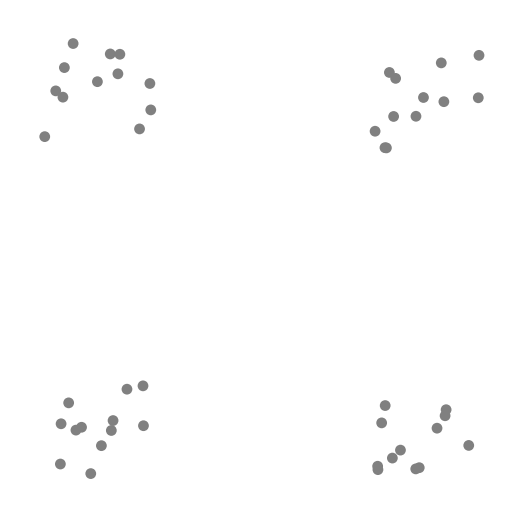

  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number please
  a whole number

In [ ]:
results = run_reader_test(reader="reader1")
results[["panel", "principle", "shown", "true_groups", "perceived_groups", "match"]]

## 3. Principles fighting: connection with and without lines
The connection panel is built so the line opposes similarity (partners are different colours) and proximity
(partners are not the nearest item). Same data, drawn twice.

NameError: name 'draw_panel' is not defined

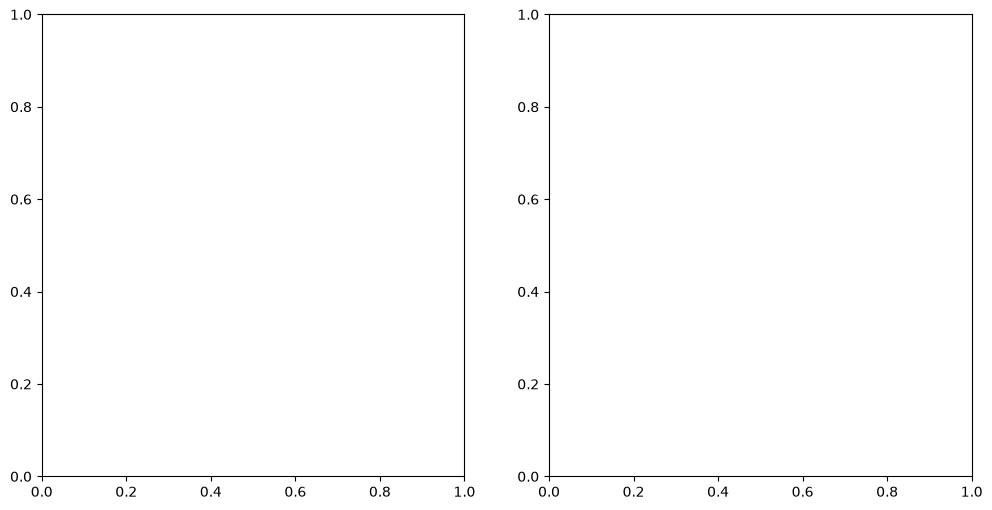

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
draw_panel(axes[0], "connection", lines=True, title=False)
draw_panel(axes[1], "connection", lines=False, title=False)
axes[0].set_title("connection - lines drawn", fontsize=13)
axes[1].set_title("connection - lines removed", fontsize=13)
fig.savefig("task2_connection_fight.png", dpi=300, bbox_inches="tight")
plt.show()

cx = results[results["panel"] == "connection"].set_index("shown")
print(f"Without lines: {cx.loc['lines off', 'perceived_groups']} groups. "
      f"With lines: {cx.loc['lines on', 'perceived_groups']} groups. (24 partner pairs = the 'connection' answer.)")

**Which principle won?** Without lines the reader saw [FILL] groups and said they grouped by [FILL]; with lines they saw [FILL].
Winner: [FILL - write what actually happened, even if connection did not win].

### Results table
| Panel | Principle | True groups | Perceived | Match |
|---|---|---|---|---|
| [FILL from the table above] | | | | |

## 4. A Gestalt principle in a real chart (tips.csv)
Grouped bar chart of mean tip by day, smokers vs non-smokers.
Left: **proximity** groups the pair (tiny gap inside a pair, big gap between pairs).
Right: same data, all gaps equal.

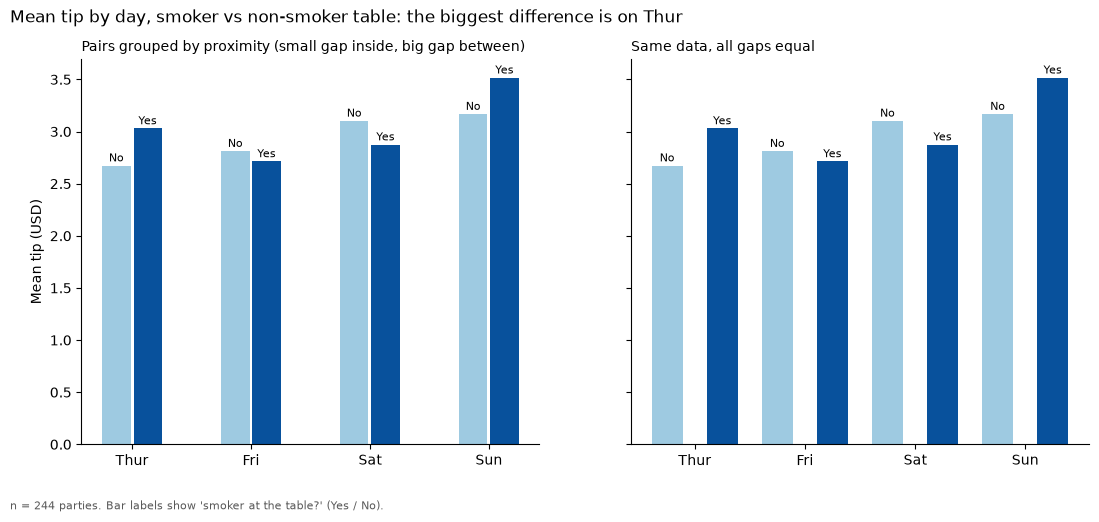

In [4]:
tips = pd.read_csv("tips.csv")
days = [d for d in ["Thur", "Fri", "Sat", "Sun"] if d in set(tips["day"])]
means = tips.groupby(["day", "smoker"])["tip"].mean().unstack().loc[days]

bar_w = 0.38
n = len(days)

# version A: bars of a pair touch (tiny gap), pairs are far apart
centres_a = np.arange(n) * 1.6
within_a = 0.04
pos_a = {"No": centres_a - (bar_w + within_a) / 2, "Yes": centres_a + (bar_w + within_a) / 2}

# version B: every bar the same distance from its neighbour
step = bar_w + 0.30
pos_b = {"No": np.arange(n) * 2 * step, "Yes": np.arange(n) * 2 * step + step}
centres_b = (pos_b["No"] + pos_b["Yes"]) / 2

gap = (means["Yes"] - means["No"]).abs()
widest = gap.idxmax()

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, pos, centres in [(ax_a, pos_a, centres_a), (ax_b, pos_b, centres_b)]:
    for smoker, colour in [("No", "#9ecae1"), ("Yes", "#08519c")]:
        ax.bar(pos[smoker], means[smoker], width=bar_w, color=colour)
        for x, v in zip(pos[smoker], means[smoker]):
            ax.text(x, v + 0.04, smoker, ha="center", fontsize=8)  # small direct label: smoker yes / no
    ax.set_xticks(centres)
    ax.set_xticklabels(days)
    ax.spines[["top", "right"]].set_visible(False)
ax_a.set_ylim(bottom=0)
ax_a.set_ylabel("Mean tip (USD)")
ax_a.set_title("Pairs grouped by proximity (small gap inside, big gap between)", fontsize=10, loc="left")
ax_b.set_title("Same data, all gaps equal", fontsize=10, loc="left")
fig.suptitle(f"Mean tip by day, smoker vs non-smoker table: the biggest difference is on {widest}",
             x=0.07, ha="left", fontsize=12)
fig.text(0.07, -0.02, f"n = {len(tips)} parties. Bar labels show 'smoker at the table?' (Yes / No).",
         fontsize=8, color="0.35")
fig.savefig("task2_tips_proximity.png", dpi=300, bbox_inches="tight")
plt.show()

Whitespace Hierarchy & Grouping via Proximity**

* **Context & Dataset:** Mean tip (USD) across days of the week (Thur, Fri, Sat, Sun), segmented by party smoking status ("No" = light blue, "Yes" = dark blue), based on $n = 244$ dining parties.


* **Detailed Breakdown:**
* **Left Plot (Grouped by Proximity):**
* *Spacing Architecture:* Small gap inside each day's pair; large gap between consecutive days.


* *Cognitive Mechanics:* Proximity immediately signals a 2-level hierarchy: Day is the primary category; smoker status is the sub-category. The eye naturally makes within-day comparisons first (e.g., observing that Sunday has the highest tipping overall and the highest smoker tipping at ~$3.52).




* **Right Plot (Same Data, All Gaps Equal):**
* *Spacing Architecture:* Uniform distance between all eight vertical bars.


* *Cognitive Mechanics:* The Gestalt proximity cue is dismantled. The viewer cannot rely on peripheral layout cues and must explicitly read the X-axis labels to decipher where "Friday" ends and "Saturday" begins.






* **Core Takeaway:** Whitespace is not empty void; it is active syntax that dictates visual relationships and cognitive grouping.


**What the reader loses in the second version:** the day pairs are no longer closer to each other than to the next day,
so the reader has to read labels and colours bar by bar to find out which bars belong to the same day. They lose the
instant grouping and the easy within-day comparison (smoker vs non-smoker). The data has not changed at all, only the gaps.

## 5. Where each principle already lives in a chart
- **Proximity:** the bars of one category sitting close together in a grouped bar chart.
- **Similarity:** the same colour for the same series across a chart, which is what a legend relies on.
- **Enclosure:** a shaded band or box around a highlighted region, such as a recession period on a time series.
- **Closure:** a dashed outline or an unfinished circle in a gauge, which the eye completes without it being drawn in full.
- **Continuity:** a line chart's line, where the eye follows the path through the points.
- **Connection:** the line joining points in a slope chart or a network diagram.

## The question: legend vs direct labelling
Direct labelling uses **proximity**: the name sits next to the mark it names.
With a legend the reader has to read a colour, hold it in working memory, travel to the plot, find the matching colour,
compare, and repeat that for every series. That is extra load that stays in working memory the whole time.
A direct label removes the lookup: the link is made by where the text is, so nothing has to be held or carried.